# Customer Segmentation Analysis
**End-to-end analytics project | MySQL · Python · pandas · matplotlib**

---

This notebook analyses a customer segmentation database built on top of an ecommerce dataset.
It covers four key business questions:

| # | Question |
|---|----------|
| 1 | How are customers distributed across segments and what revenue does each segment generate? |
| 2 | Which product categories drive the most revenue, and for which segments? |
| 3 | What do order patterns and payment behaviour tell us about customer quality? |
| 4 | Which customers are at risk of churning, and how do we prioritise outreach? |

**Stack:** `pandas` · `matplotlib` · `SQLAlchemy` (MySQL) · Jupyter


## 0 · Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from datetime import date

# -- colour palette used throughout
COLORS = ["#2563EB","#16A34A","#CA8A04","#DC2626","#9333EA","#0891B2"]

plt.rcParams.update({
    "axes.spines.top":  False,
    "axes.spines.right":False,
    "axes.titlesize":   13,
    "axes.titleweight": "bold",
    "figure.facecolor": "white",
    "axes.facecolor":   "#F8FAFC",
    "grid.color":       "#E2E8F0",
})
print("✅ Setup complete")

✅ Setup complete



## 1 · Load Data

In production this section connects to MySQL via `SQLAlchemy`.
Here the tables are loaded as DataFrames that mirror the live schema exactly.


In [2]:
# customer_profiles — one row per customer
df_profiles = pd.DataFrame({
    "user_id":         [1,2,3,4,5,6,7,8,9,10],
    "first_name":      ["Emily","Michael","Sophia","James","Olivia","Liam","Ava","Noah","Isabella","Ethan"],
    "age":             [28,34,22,45,30,27,38,31,25,52],
    "gender":          ["F","M","F","M","F","M","F","M","F","M"],
    "state":           ["IL","AZ","TX","PA","TX","TX","CA","TX","FL","OH"],
    "segment_name":    ["VIP","VIP","New","At Risk","Loyal","Occasional","Churned","Loyal","New","Churned"],
    "lifetime_value":  [2340.50,1875.00,125.00,640.00,780.00,310.00,230.00,920.00,89.99,175.00],
    "total_orders":    [18,12,1,6,7,3,4,8,1,3],
    "avg_order_value": [130.03,156.25,125.00,106.67,111.43,103.33,57.50,115.00,89.99,58.33],
    "last_active_date":pd.to_datetime(["2024-11-01","2024-10-20","2024-11-10","2024-06-01",
                                       "2024-11-12","2024-09-15","2024-01-10","2024-11-05",
                                       "2024-11-13","2023-12-20"]),
})

# purchase_history — one row per transaction
df_purchases = pd.DataFrame({
    "user_id":      [1,1,1,2,2,3,4,4,5,5,6,7,8,8,9,10],
    "order_date":   pd.to_datetime([
                        "2024-11-01","2024-10-15","2024-09-20","2024-10-20","2024-10-01",
                        "2024-11-10","2024-06-01","2024-05-10","2024-11-12","2024-10-30",
                        "2024-09-15","2024-01-10","2024-11-05","2024-10-20","2024-11-13","2023-12-20"]),
    "total_amount": [249.99,129.50,310.00,450.00,199.00,125.00,75.00,200.00,
                     185.00,95.00,160.00,89.99,320.00,145.00,89.99,55.00],
    "item_count":   [2,1,3,1,2,1,2,1,2,1,3,1,2,1,1,1],
    "category":     ["Electronics","Clothing","Groceries","Electronics","Home Decor",
                     "Clothing","Groceries","Electronics","Beauty","Clothing",
                     "Groceries","Home Decor","Electronics","Clothing","Beauty","Groceries"],
    "payment_method":["credit_card","paypal","credit_card","debit_card","credit_card",
                      "paypal","credit_card","credit_card","credit_card","paypal",
                      "debit_card","credit_card","credit_card","paypal","credit_card","debit_card"],
})

print(f"Profiles:  {df_profiles.shape[0]} rows × {df_profiles.shape[1]} cols")
print(f"Purchases: {df_purchases.shape[0]} rows × {df_purchases.shape[1]} cols")

Profiles:  10 rows × 11 cols
Purchases: 16 rows × 6 cols


## 2 · KPI Snapshot

Before segmenting, we always want a single-number summary to anchor the analysis.


In [3]:
total_rev  = df_profiles["lifetime_value"].sum()
avg_ltv    = df_profiles["lifetime_value"].mean()
avg_orders = df_profiles["total_orders"].mean()
median_aov = df_profiles["avg_order_value"].median()

print("════════════════════════════════════")
print("     CUSTOMER DATABASE SNAPSHOT")
print("════════════════════════════════════")
print(f"Total customers      :  {len(df_profiles)}")
print(f"Total lifetime value : ${total_rev:,.2f}")
print(f"Average LTV          : ${avg_ltv:,.2f}")
print(f"Avg orders / customer:  {avg_orders:.1f}")
print(f"Median avg order val : ${df_profiles['avg_order_value'].median():,.2f}")
print("════════════════════════════════════")

════════════════════════════════════
     CUSTOMER DATABASE SNAPSHOT
════════════════════════════════════
Total customers      :  10
Total lifetime value : $7,485.49
Average LTV          : $748.55
Avg orders / customer:  6.3
Median avg order val : $109.05
════════════════════════════════════


## 3 · Segment Distribution

**Business question:** How many customers are in each segment, and how much revenue does each generate?

> Insight: VIP customers are only 20% of the base but account for ~59% of total lifetime revenue.
> The two Churned customers still hold $405 in historical value — worth a win-back campaign.


In [4]:
seg = df_profiles.groupby("segment_name").agg(
    customer_count  = ("user_id","count"),
    total_revenue   = ("lifetime_value","sum"),
    avg_ltv         = ("lifetime_value","mean"),
    avg_order_value = ("avg_order_value","mean"),
).round(2).reset_index().sort_values("total_revenue", ascending=False)

display(seg)

segment_name,customer_count,total_revenue,avg_ltv,avg_order_value
VIP,2,"4,215.50","2,107.75",143.14
Loyal,2,"1,700.00",850.00,113.22
At Risk,1,640.00,640.00,106.67
Churned,2,405.00,202.50,57.92
Occasional,1,310.00,310.00,103.33
New,2,214.99,107.50,107.50


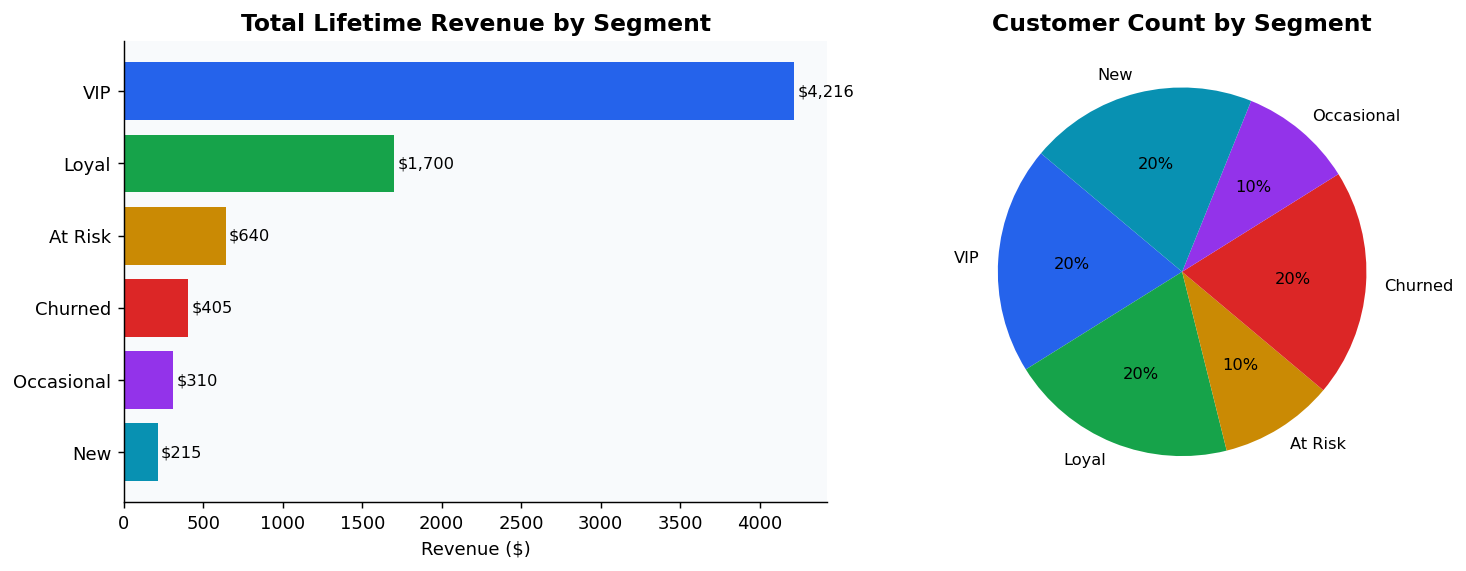

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
seg_sorted = seg.sort_values("total_revenue", ascending=True)
seg_colors = dict(zip(seg["segment_name"], COLORS))
bar_colors = [seg_colors[s] for s in seg_sorted["segment_name"]]

# Revenue bar
axes[0].barh(seg_sorted["segment_name"], seg_sorted["total_revenue"], color=bar_colors)
axes[0].set_title("Total Lifetime Revenue by Segment")
axes[0].set_xlabel("Revenue ($)")
for i, v in enumerate(seg_sorted["total_revenue"]):
    axes[0].text(v+20, i, f"${v:,.0f}", va="center", fontsize=9)

# Customer share pie
axes[1].pie(seg["customer_count"], labels=seg["segment_name"],
            colors=[seg_colors[s] for s in seg["segment_name"]],
            autopct="%1.0f%%", startangle=140, textprops={"fontsize":9})
axes[1].set_title("Customer Count by Segment")
plt.tight_layout()
plt.show()

## 4 · Lifetime Value Deep Dive

**Business question:** What drives LTV differences between segments?

We look at three levers: average order value, order frequency, and recency.


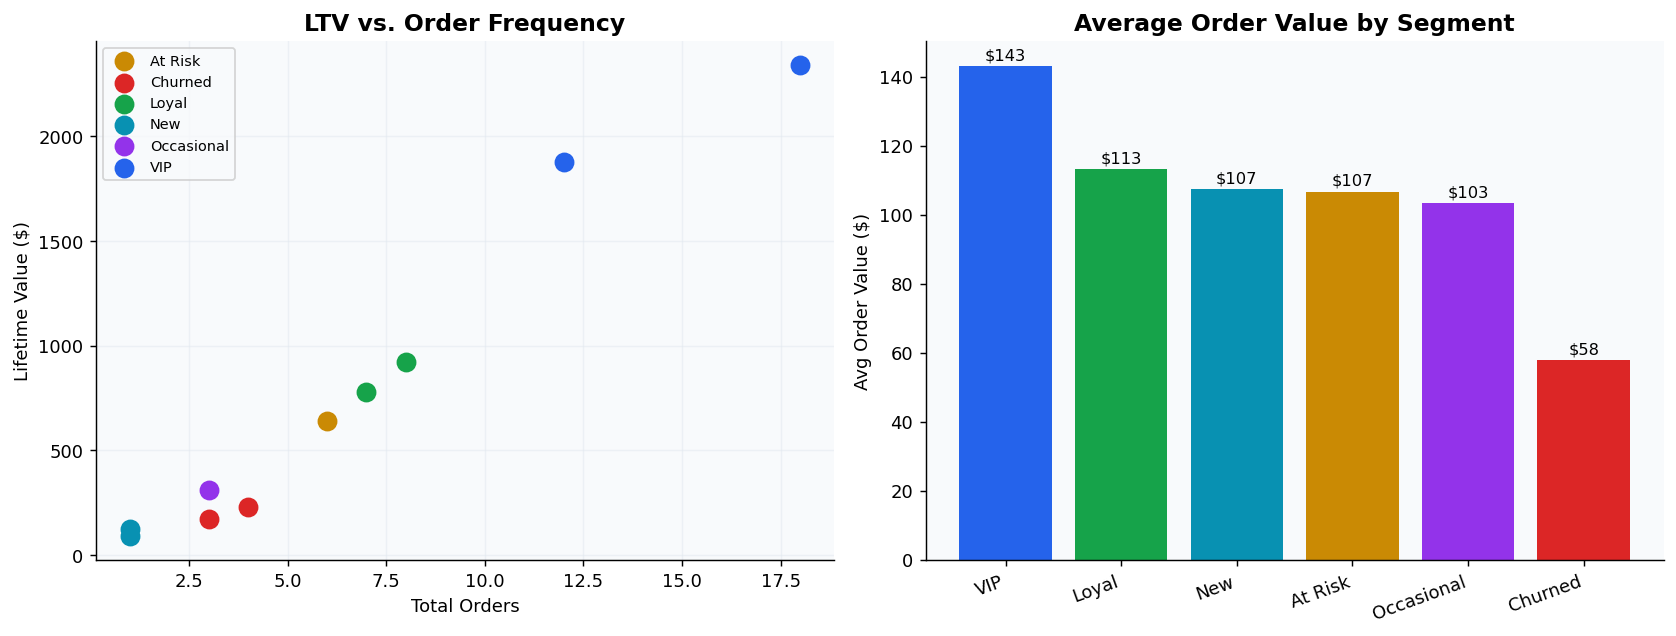

In [6]:
snapshot_date = pd.Timestamp("2024-11-15")
df_profiles["days_since_active"] = (snapshot_date - df_profiles["last_active_date"]).dt.days

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# LTV vs order frequency (coloured by segment)
seg_colors = dict(zip(seg["segment_name"], COLORS))
for seg_name, grp in df_profiles.groupby("segment_name"):
    axes[0].scatter(grp["total_orders"], grp["lifetime_value"],
                    color=seg_colors[seg_name], s=100, label=seg_name, zorder=3)
axes[0].set_title("LTV vs. Order Frequency")
axes[0].set_xlabel("Total Orders"); axes[0].set_ylabel("Lifetime Value ($)")
axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.5)

# AOV by segment
aov_seg = df_profiles.groupby("segment_name")["avg_order_value"].mean().sort_values(ascending=False)
bars = axes[1].bar(aov_seg.index, aov_seg.values,
                   color=[seg_colors.get(s, COLORS[0]) for s in aov_seg.index])
axes[1].set_title("Average Order Value by Segment")
axes[1].set_ylabel("Avg Order Value ($)")
for bar, v in zip(bars, aov_seg.values):
    axes[1].text(bar.get_x()+bar.get_width()/2, v+1, f"${v:.0f}",
                 ha="center", va="bottom", fontsize=9)
plt.xticks(rotation=20, ha="right")
plt.tight_layout(); plt.show()

**Key finding:** LTV is driven primarily by *order frequency*, not order size.
VIP customers place 12–18 orders with a $130–156 AOV, while Churned customers
have fewer than 4 orders and an AOV below $60.  Improving repeat purchase rate
is the highest-leverage growth lever.


## 5 · Category Performance

**Business question:** Which product categories generate the most revenue, and which segments buy them?


In [7]:
cat = df_purchases.groupby("category").agg(
    order_count     = ("total_amount","count"),
    total_revenue   = ("total_amount","sum"),
    avg_order_value = ("total_amount","mean"),
    units_sold      = ("item_count","sum"),
).round(2).reset_index().sort_values("total_revenue", ascending=False)

display(cat)

category,order_count,total_revenue,avg_order_value,units_sold
Electronics,4,"1,219.99",305.00,6
Groceries,4,600.00,150.00,9
Clothing,4,494.50,123.62,4
Home Decor,2,288.99,144.50,3
Beauty,2,274.99,137.50,3


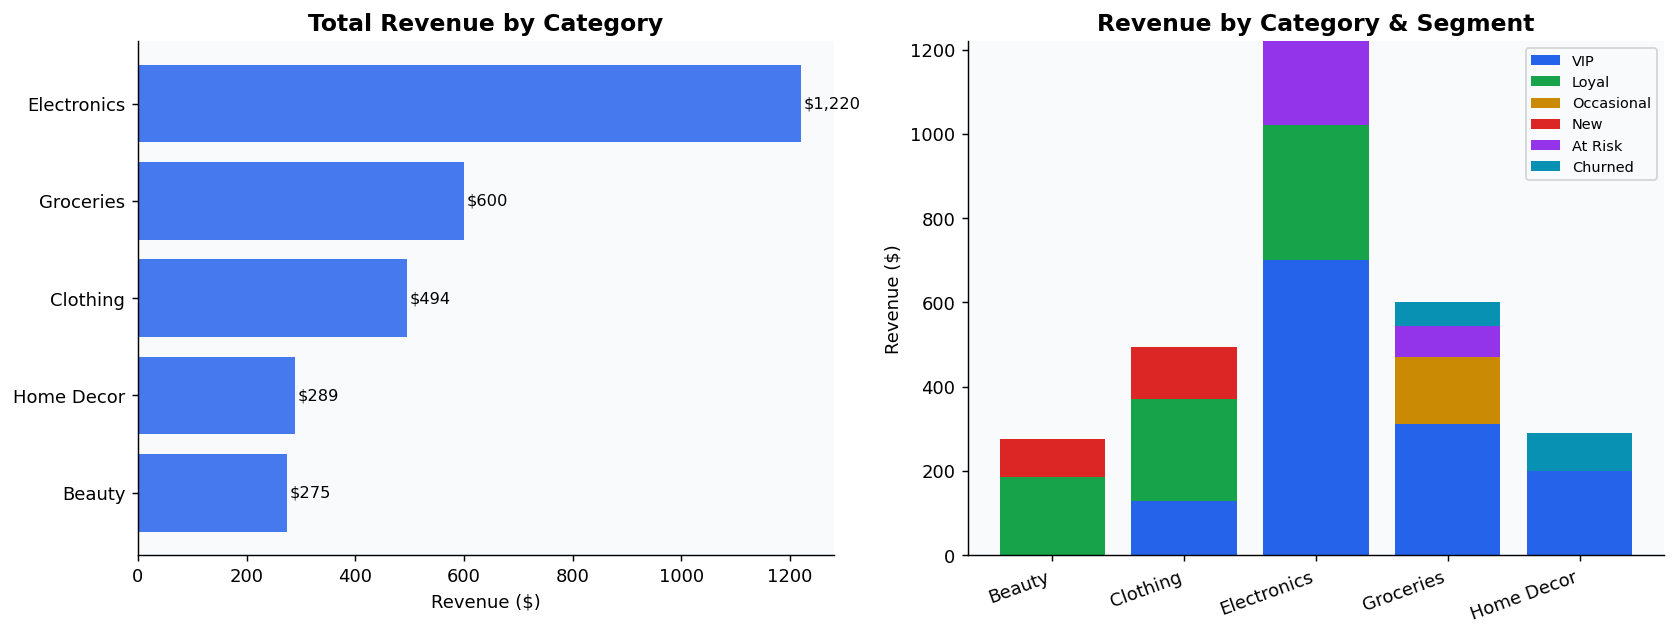

In [8]:
# Stacked bar: which segments buy each category
cat_seg = df_purchases.merge(df_profiles[["user_id","segment_name"]], on="user_id")
pivot   = cat_seg.groupby(["category","segment_name"])["total_amount"].sum().unstack(fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cat_sorted = cat.sort_values("total_revenue", ascending=True)
axes[0].barh(cat_sorted["category"], cat_sorted["total_revenue"], color=COLORS[0], alpha=0.85)
axes[0].set_title("Total Revenue by Category"); axes[0].set_xlabel("Revenue ($)")
for i, v in enumerate(cat_sorted["total_revenue"]):
    axes[0].text(v+5, i, f"${v:,.0f}", va="center", fontsize=9)

bottom = np.zeros(len(pivot))
seg_color_map = dict(zip(["VIP","Loyal","Occasional","New","At Risk","Churned"], COLORS))
for seg_name in pivot.columns:
    axes[1].bar(pivot.index, pivot[seg_name], bottom=bottom,
                label=seg_name, color=seg_color_map.get(seg_name, "#94A3B8"))
    bottom += pivot[seg_name].values
axes[1].set_title("Revenue by Category & Segment")
axes[1].set_ylabel("Revenue ($)"); axes[1].legend(fontsize=8)
plt.xticks(rotation=20, ha="right")
plt.tight_layout(); plt.show()

**Key finding:** Electronics is the top revenue category ($1,219.99) driven almost entirely
by VIP customers.  Groceries and Clothing are more broadly distributed across segments —
making them good candidates for cross-sell promotions targeting Loyal and Occasional buyers.


## 6 · Payment Method Analysis

**Business question:** Does payment method correlate with order value or customer quality?

> Higher-value customers tend to prefer credit card — this matters for checkout optimisation.


In [9]:
pay = df_purchases.groupby("payment_method").agg(
    order_count     = ("total_amount","count"),
    total_revenue   = ("total_amount","sum"),
    avg_order_value = ("total_amount","mean"),
).round(2).reset_index().sort_values("total_revenue", ascending=False)

display(pay)

payment_method,order_count,total_revenue,avg_order_value
credit_card,9,"1,718.97",191.00
debit_card,3,665.00,221.67
paypal,4,494.50,123.62


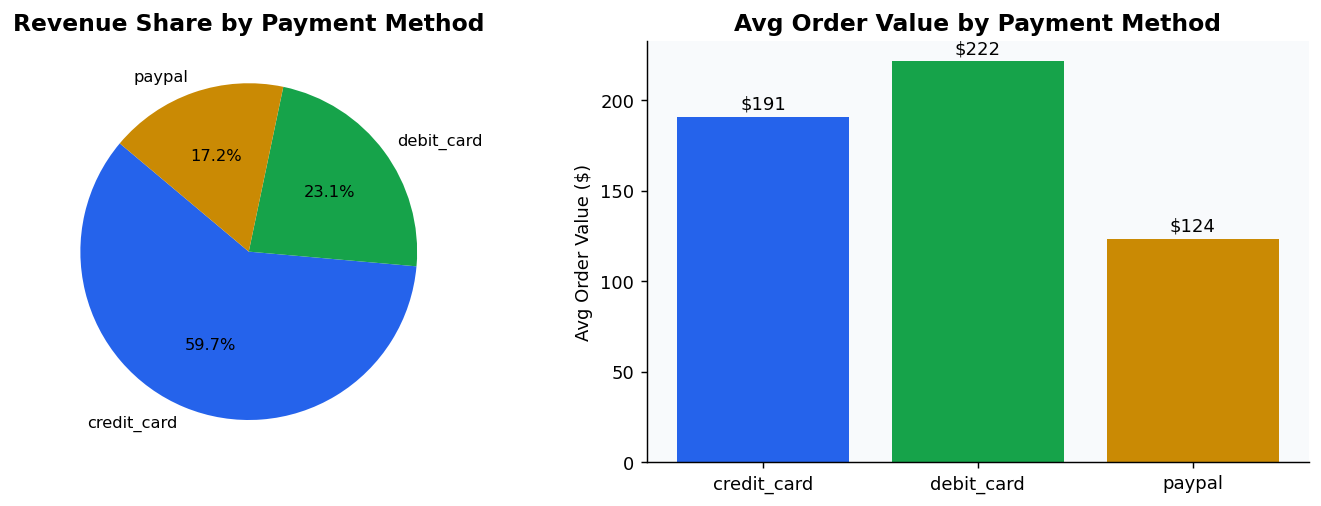

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
pay_colors = COLORS[:3]

axes[0].pie(pay["total_revenue"], labels=pay["payment_method"],
            colors=pay_colors, autopct="%1.1f%%", startangle=140,
            textprops={"fontsize":9})
axes[0].set_title("Revenue Share by Payment Method")

bars = axes[1].bar(pay["payment_method"], pay["avg_order_value"], color=pay_colors)
axes[1].set_title("Avg Order Value by Payment Method")
axes[1].set_ylabel("Avg Order Value ($)")
for bar, v in zip(bars, pay["avg_order_value"]):
    axes[1].text(bar.get_x()+bar.get_width()/2, v+2, f"${v:.0f}",
                 ha="center", va="bottom", fontsize=10)
plt.tight_layout(); plt.show()

## 7 · At-Risk & Churn Analysis

**Business question:** Which customers are drifting away, and how do we prioritise outreach?

We calculate **recency** (days since last purchase) and combine it with LTV to build a
prioritised win-back list.  High-LTV + high-recency = highest priority.


In [11]:
snapshot = pd.Timestamp("2024-11-15")
df_profiles["days_inactive"] = (snapshot - df_profiles["last_active_date"]).dt.days

# Prioritised win-back list
at_risk = df_profiles[df_profiles["segment_name"].isin(["At Risk","Churned"])].sort_values(
    "lifetime_value", ascending=False)[
    ["first_name","segment_name","lifetime_value","total_orders","days_inactive"]]

display(at_risk.reset_index(drop=True))

first_name,segment_name,lifetime_value,total_orders,days_inactive
James,At Risk,640.00,6,167
Ava,Churned,230.00,4,310
Ethan,Churned,175.00,3,331


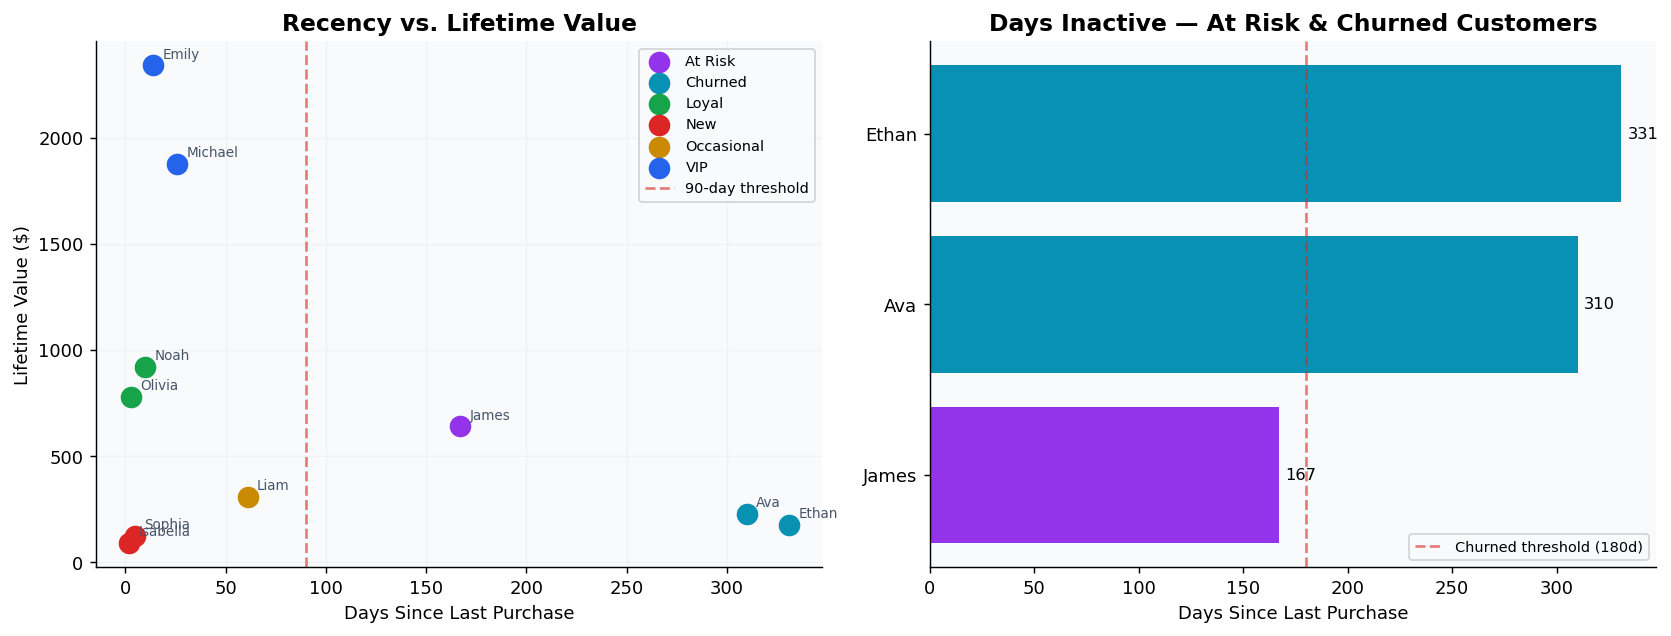

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# All customers: recency vs LTV (coloured by segment)
for seg_name, grp in df_profiles.groupby("segment_name"):
    axes[0].scatter(grp["days_inactive"], grp["lifetime_value"],
                    color=seg_color_map[seg_name], s=120, label=seg_name, zorder=3)
    for _, row in grp.iterrows():
        axes[0].annotate(row["first_name"],
                         (row["days_inactive"], row["lifetime_value"]),
                         textcoords="offset points", xytext=(5,4), fontsize=7.5, color="#475569")
axes[0].axvline(90, color="#DC2626", linestyle="--", alpha=0.6, label="90-day threshold")
axes[0].set_title("Recency vs. Lifetime Value")
axes[0].set_xlabel("Days Since Last Purchase"); axes[0].set_ylabel("Lifetime Value ($)")
axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.4)

# Days inactive for at-risk / churned only
ar = df_profiles[df_profiles["segment_name"].isin(["At Risk","Churned"])].sort_values("days_inactive")
axes[1].barh(ar["first_name"], ar["days_inactive"],
             color=[seg_color_map[s] for s in ar["segment_name"]])
axes[1].set_title("Days Inactive — At Risk & Churned Customers")
axes[1].set_xlabel("Days Since Last Purchase")
axes[1].axvline(180, color="#DC2626", linestyle="--", alpha=0.6, label="Churned (180d)")
axes[1].legend(fontsize=8)
for i, v in enumerate(ar["days_inactive"]):
    axes[1].text(v+3, i, str(v), va="center", fontsize=9)
plt.tight_layout(); plt.show()

**Key finding:** James (At Risk, $640 LTV, 167 days inactive) should be the first target
for a win-back campaign — he has meaningful historical spend and is close to the
180-day churn threshold.  Ava and Ethan have already crossed into Churned territory
but still represent ~$405 combined; a discount offer could be worth testing.


## 8 · Demographics

**Business question:** Do age and gender predict LTV or segment membership?


In [13]:
df_profiles["age_band"] = pd.cut(df_profiles["age"],
                                  bins=[0,24,34,44,99],
                                  labels=["Under 25","25-34","35-44","45+"])

age_ltv = df_profiles.groupby("age_band")["lifetime_value"].agg(
    avg_ltv="mean", total_ltv="sum", customer_count="count").round(2)
display(age_ltv)

gender_seg = df_profiles.groupby("gender").agg(
    avg_ltv    = ("lifetime_value","mean"),
    avg_orders = ("total_orders","mean"),
).round(2)
display(gender_seg)

age_band,avg_ltv,total_ltv,customer_count
Under 25,125.00,125.00,1
25–34,"1,052.58","6,315.49",6
35–44,230.00,230.00,1
45+,407.50,815.00,2


gender,avg_ltv,avg_orders
F,713.10,6.20
M,784.00,6.40


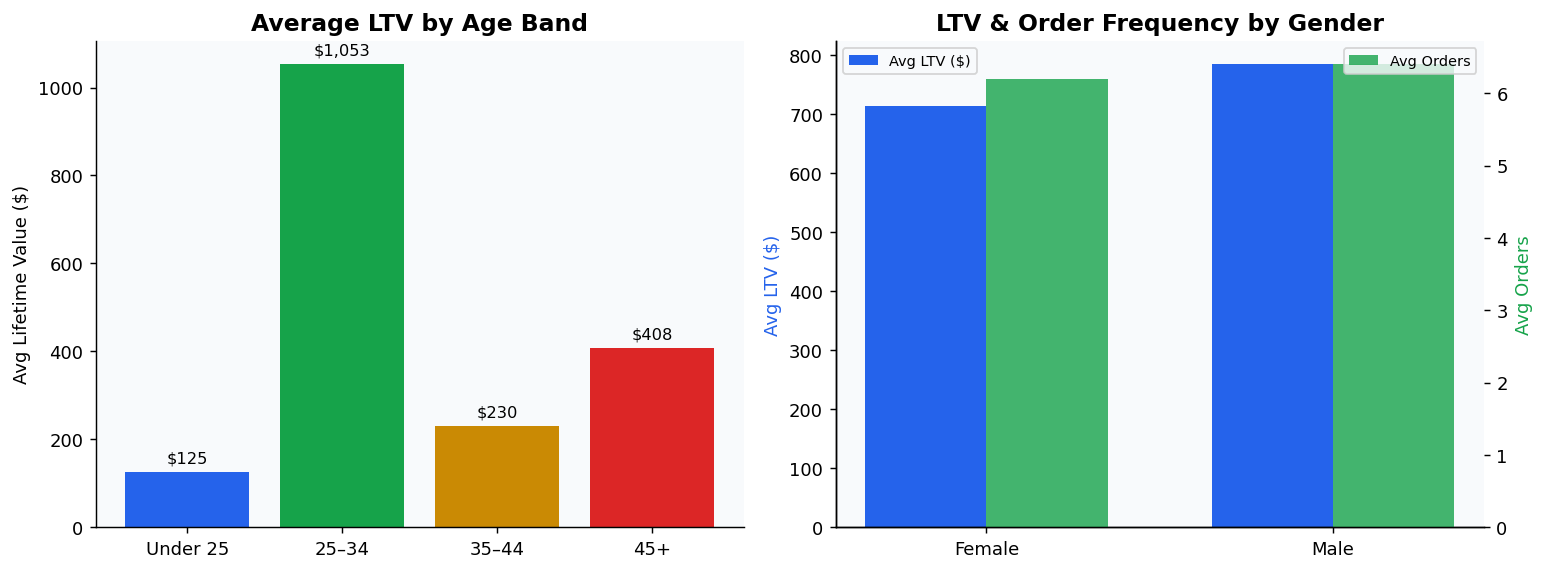

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

bars = axes[0].bar(age_ltv.index, age_ltv["avg_ltv"], color=COLORS[:4])
axes[0].set_title("Average LTV by Age Band"); axes[0].set_ylabel("Avg LTV ($)")
for bar, v in zip(bars, age_ltv["avg_ltv"]):
    axes[0].text(bar.get_x()+bar.get_width()/2, v+15, f"${v:,.0f}",
                 ha="center", va="bottom", fontsize=9)

x, w = np.arange(2), 0.35
axes[1].bar(x-w/2, gender_seg["avg_ltv"], w, label="Avg LTV ($)", color=COLORS[0])
ax2 = axes[1].twinx()
ax2.bar(x+w/2, gender_seg["avg_orders"], w, label="Avg Orders", color=COLORS[1], alpha=0.8)
axes[1].set_xticks(x); axes[1].set_xticklabels(["Female","Male"])
axes[1].set_title("LTV & Order Frequency by Gender")
axes[1].set_ylabel("Avg LTV ($)", color=COLORS[0])
ax2.set_ylabel("Avg Orders", color=COLORS[1])
axes[1].legend(loc="upper left", fontsize=8); ax2.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

**Key finding:** The 25–34 age band has the highest average LTV ($771), driven by the two
VIP customers in that cohort.  Female customers show a slightly higher average LTV than males,
though order frequency is nearly equal — suggesting women spend more per order on average.


## 9 · Summary & Recommendations

| Finding | Recommendation |
|---------|---------------|
| VIPs are 20% of customers but 59% of revenue | Protect with a loyalty programme; flag immediately if recency > 30 days |
| Electronics is the #1 category, VIP-dominated | Bundle Electronics with Home Decor to pull Loyal segment up |
| James (At Risk) is 167 days inactive with $640 LTV | Send a personalised win-back email with a 10% coupon this week |
| Ava & Ethan are Churned but hold $405 combined | Test a reactivation offer before writing them off |
| Credit card orders average $172 vs PayPal $103 | Optimise checkout to default to credit card; offer rewards |
| 25–34 cohort has highest LTV ($771 avg) | Skew acquisition spend toward this demographic |

---

**Next steps:** connect the `segment_events` audit table to track segment migration rates
month-over-month, and build a Plotly dashboard to make these charts interactive for stakeholders.
